# Project #1
## Regression Analysis

**Semester : 2026 Fall**\
**Course : DATA 555 (Fundamentals of Data Science and AI)**\

## 1. Data Preparation
### 1-1. Data Load

In [1]:
import pandas as pd
df_raw = pd.read_csv("./Data/TSLA.csv")

In [2]:
df_raw

,Date,Open,High,Low,Close,Adj Close,Volume
0,2010-06-29,19.000000,25.000000,17.540001,23.889999,23.889999,18766300
1,2010-06-30,25.790001,30.420000,23.299999,23.830000,23.830000,17187100
2,2010-07-01,25.000000,25.920000,20.270000,21.959999,21.959999,8218800
3,2010-07-02,23.000000,23.100000,18.709999,19.200001,19.200001,5139800
4,2010-07-06,20.000000,20.000000,15.830000,16.110001,16.110001,6866900
...,...,...,...,...,...,...,...
2411,2020-01-28,568.489990,576.809998,558.080017,566.900024,566.900024,11788500
2412,2020-01-29,575.690002,589.799988,567.429993,580.989990,580.989990,17801500
2413,2020-01-30,632.419983,650.880005,618.000000,640.809998,640.809998,29005700
2414,2020-01-31,640.000000,653.000000,632.520020,650.570007,650.570007,15719300


The dataset contains seven fields(date, open, high, low, close low, adjusted close, and volume)for the period from June 29, 2010, to February 3, 2020.

### 1-2. Data Analysis

In [3]:
df_raw.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2416 entries, 0 to 2415
Data columns (total 7 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   Date       2416 non-null   object 
 1   Open       2416 non-null   float64
 2   High       2416 non-null   float64
 3   Low        2416 non-null   float64
 4   Close      2416 non-null   float64
 5   Adj Close  2416 non-null   float64
 6   Volume     2416 non-null   int64  
dtypes: float64(5), int64(1), object(1)
memory usage: 132.2+ KB


Convert the Date column from a string to a datetime type to make the chart’s axis labels cleaner.

In [4]:
df_raw['Date'] = pd.to_datetime(df_raw['Date'])
df_raw = df_raw.sort_values("Date").reset_index(drop=True)

In [5]:
df_raw.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2416 entries, 0 to 2415
Data columns (total 7 columns):
 #   Column     Non-Null Count  Dtype         
---  ------     --------------  -----         
 0   Date       2416 non-null   datetime64[ns]
 1   Open       2416 non-null   float64       
 2   High       2416 non-null   float64       
 3   Low        2416 non-null   float64       
 4   Close      2416 non-null   float64       
 5   Adj Close  2416 non-null   float64       
 6   Volume     2416 non-null   int64         
dtypes: datetime64[ns](1), float64(5), int64(1)
memory usage: 132.2 KB


Check for duplicate and missing values.

In [6]:
df_raw.duplicated().sum()

np.int64(0)

In [7]:
df_raw.isna().mean().mul(100)

Date         0.0
Open         0.0
High         0.0
Low          0.0
Close        0.0
Adj Close    0.0
Volume       0.0
dtype: float64

Check the correlation coefficients. All variables have high correlations except for Volume. This project will predict the Close value, and since Adj Close is perfectly correlated with Close, exclude Adj Close from the analysis. Instead, add a field for the change from the previous day.

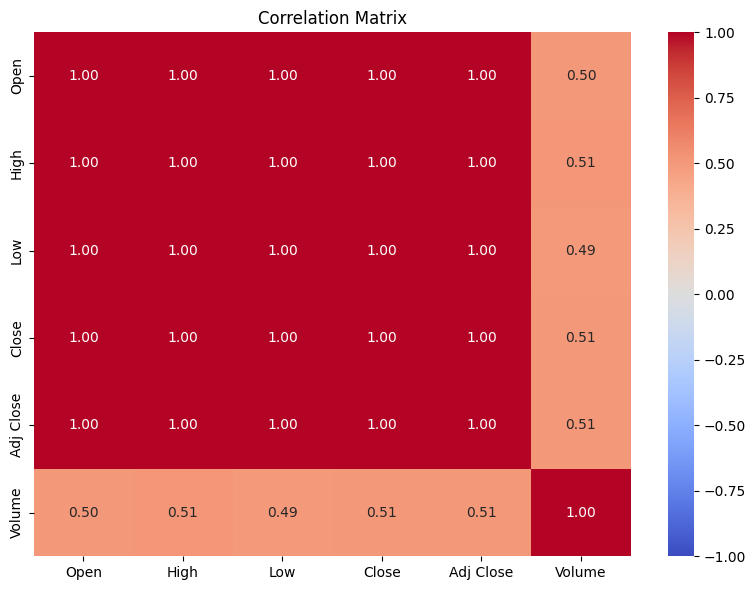

In [8]:
import matplotlib.pyplot as plt
import seaborn as sns

corr = (
    df_raw
    .select_dtypes(include="number")
    .corr()
)

plt.figure(figsize=(8, 6))
sns.heatmap(corr, annot=True, cmap="coolwarm", vmin=-1, vmax=1, fmt=".2f")
plt.title("Correlation Matrix")
plt.tight_layout()
plt.show()

In [9]:
corr

,Open,High,Low,Close,Adj Close,Volume
Open,1.000000,0.999425,0.999575,0.998886,0.998886,0.501762
High,0.999425,1.000000,0.999389,0.999640,0.999640,0.512944
Low,0.999575,0.999389,1.000000,0.999447,0.999447,0.493496
Close,0.998886,0.999640,0.999447,1.000000,1.000000,0.505169
Adj Close,0.998886,0.999640,0.999447,1.000000,1.000000,0.505169
Volume,0.501762,0.512944,0.493496,0.505169,0.505169,1.000000


In [10]:
df_raw.drop(columns=["Adj Close"], inplace=True)

In [11]:
df_raw["Change"] = df_raw["Close"].diff()

Use regression scatter plot to assess how well each variable fits a linear regression with the target, the next business day’s Close.

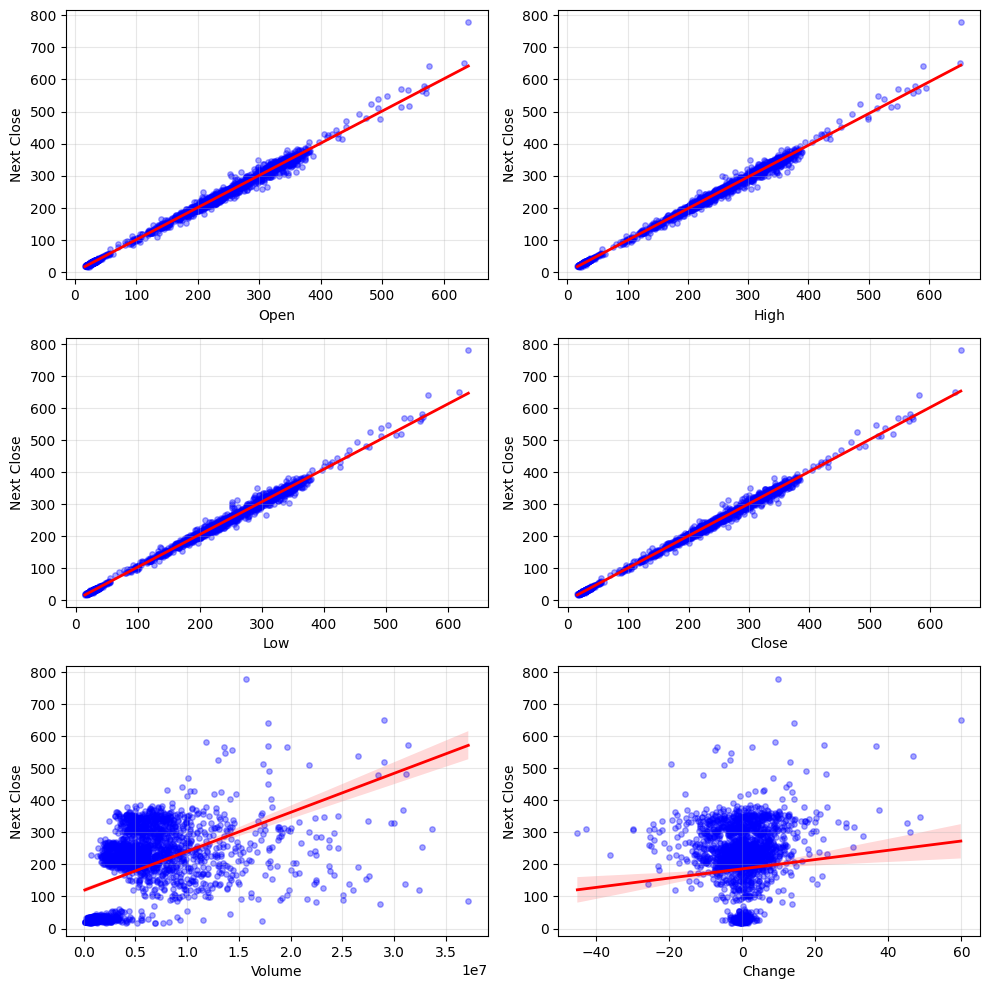

In [12]:
import seaborn as sns
df_eda = df_raw.dropna().copy()
df_eda["Next Close"] = df_eda["Close"].shift(-1)
df_eda = df_eda.dropna()
features_to_check = ["Open", "High", "Low", "Close", "Volume","Change"]
fig, axes = plt.subplots(3, 2, figsize=(10, 10))
axes = axes.flatten()
for idx, col in enumerate(features_to_check):
    sns.regplot(
        data=df_eda,
        x=col,
        y="Next Close",
        ax=axes[idx],
        scatter_kws={"alpha": 0.35, "color": "blue", "s": 15},
        line_kws={"color": "red", "linewidth": 2}
    )
    axes[idx].set_xlabel(col, fontsize=10)
    axes[idx].set_ylabel("Next Close", fontsize=10)
    axes[idx].grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

Since Open, High, Low, and Close show nearly perfect linear relationships, linear regression may be good solution for this prediction.
Volume has a weaker relationship, while Change appears to have little to no relationship.

For prediction, using only Close, which shows a strong linear relationship, may be sufficient. 
However, I’ll use all six features to compare multiple linear regression with a ridge regression model for observing how the regulation affect to this problem.

### 1-3. Data Cleaning

The original dataset has no missing values, but adding the Change field creates a missing value in the first row. Remove that row.

In [13]:
df_raw.isna().mean().mul(100)

Date      0.000000
Open      0.000000
High      0.000000
Low       0.000000
Close     0.000000
Volume    0.000000
Change    0.041391
dtype: float64

In [14]:
df_clean = df_raw.dropna().copy()

## 2. Regression Analysis
### 2-1. Split data into Train set and Test set

To prepare the dataset for model training and testing, copy the cleaned dataset and add a “Next Close” column as the prediction target. 

Then, use the final 20% of the data for testing. Because this is time-series data, preserve the original order.

In [15]:
df_model = df_clean.copy()
df_model["Next Close"] = df_model["Close"].shift(-1)

df_model = df_model.dropna().reset_index(drop=True)

features = ["Open", "High", "Low", "Close", "Volume" ,"Change"]
X = df_model[features]
y = df_model["Next Close"]

In [16]:

split_idx = int(len(df_model) * 0.8)
X_train, X_test = X.iloc[:split_idx], X.iloc[split_idx:]
y_train, y_test = y.iloc[:split_idx], y.iloc[split_idx:]
dates_test = df_model.loc[split_idx:, "Date"]

### 2-2. Feature Scaling

Scaling the training data. To prevent information from future data from leaking into the model during training, scaling should be performed after separating the test data.

In [17]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

### 2-3. Model traning and prediction from the models
Train the model on the prepared data, then use the test set to generate predictions.


I plan to compare multiple linear regression with Ridge regression. 
To evaluate how the Ridge model performs with different hyperparameter values, I selected two values: 0.05 and 1.0.

In [18]:
from sklearn.linear_model import LinearRegression, Ridge

# Model 1: Multiple Linear Regression
lr_model = LinearRegression()
lr_model.fit(X_train_scaled, y_train)

# Model 2-1: Ridge Regression (alpha = 0.05)
ridge_model_1 = Ridge(alpha=0.05)
ridge_model_1.fit(X_train_scaled, y_train)

# Model 2-2: Ridge Regression (alpha = 1.0)
ridge_model_2 = Ridge(alpha=1.0)
ridge_model_2.fit(X_train_scaled, y_train)

y_pred_lr = lr_model.predict(X_test_scaled)
y_pred_ridge_1 = ridge_model_1.predict(X_test_scaled)
y_pred_ridge_2 = ridge_model_2.predict(X_test_scaled)

### 2-4. Evalutation
I use MAE, RMSE, and the R² score to evaluate model performance. 

Each metric was selected for a specific reason

- MAE : measures the average absolute difference between the predicted and actual values.
- RMSE: Measures prediction error in the target variable’s units, with larger errors penalized more heavily.
- R² : indicates how much of the variation in the target values is explained by the model.

In [19]:
import numpy as np
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

def evaluate(y_true, y_pred, model_name):
    mae = mean_absolute_error(y_true, y_pred)
    mse = mean_squared_error(y_true, y_pred)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_true, y_pred)
    return {"Model": model_name, "MAE": mae, "RMSE": rmse, "R2 Score": r2}

results = [
    evaluate(y_test, y_pred_lr, "Multiple Linear Regression"),
    evaluate(y_test, y_pred_ridge_1, "Ridge Regression (alpha=0.05)"),
    evaluate(y_test, y_pred_ridge_2, "Ridge Regression (alpha=1.0)"),
]

eval_df = pd.DataFrame(results)
display(eval_df.round(4))

,Model,MAE,RMSE,R2 Score
0,Multiple Linear Regression,7.6461,12.3200,0.9706
1,Ridge Regression (alpha=0.05),7.6424,12.3596,0.9704
2,Ridge Regression (alpha=1.0),7.8426,12.6741,0.9689


### 2-5. Result Visualization
To visualize the evaluation results, I used line plots to compare predicted values with actual values and to examine each model’s residuals. 

I also used bar charts to compare the models’ coefficients and examine the direction and magnitude of each feature’s estimated effect on the target.

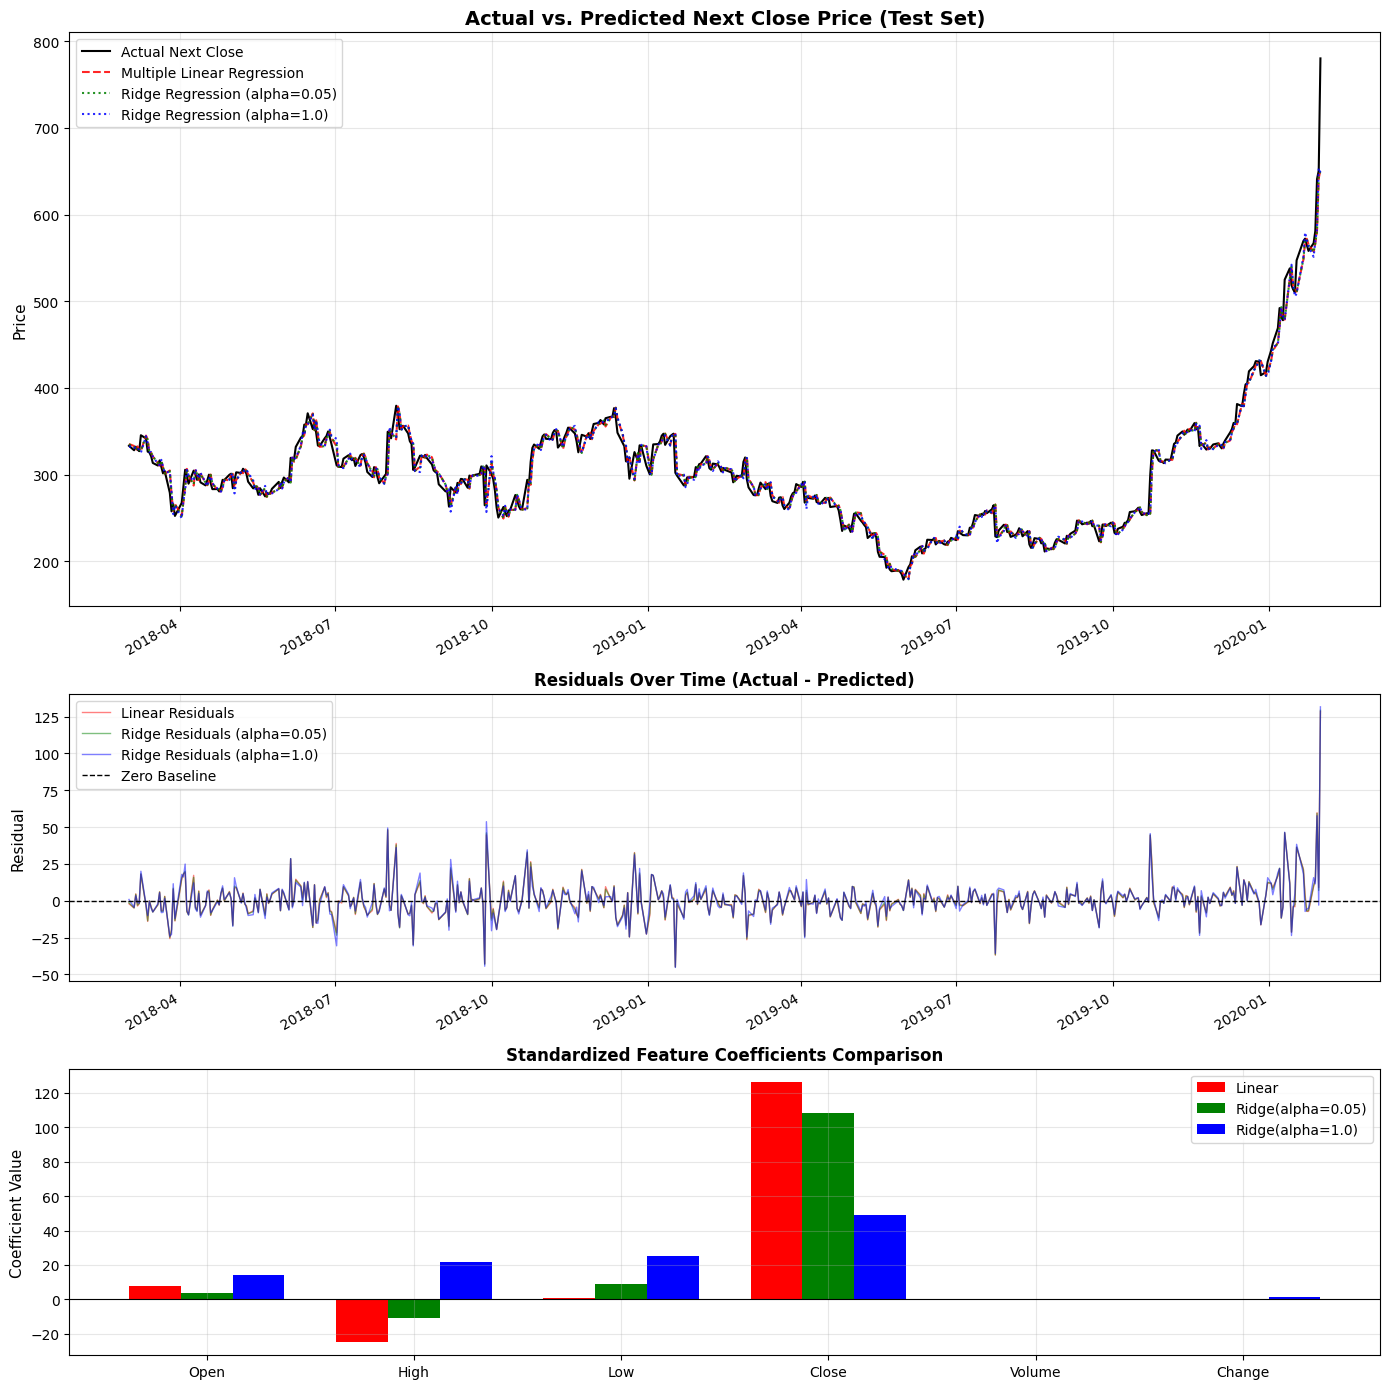

Feature Coefficients Table


,Feature,Linear,Ridge_1,Ridge_2
0,Open,7.8648,3.7969,14.1877
1,High,-24.9205,-10.9060,21.8744
2,Low,0.6604,9.1348,25.3701
3,Close,126.5413,108.1373,48.7739
4,Volume,0.4408,0.3870,0.2095
5,Change,0.0081,0.2353,1.3363


In [20]:
dates_test_dt = pd.to_datetime(dates_test)

fig, axes = plt.subplots(3, 1, figsize=(14, 14), gridspec_kw={"height_ratios": [2, 1, 1]})

# Subplot 1: Actual vs Predicted Next Close
axes[0].plot(dates_test_dt, y_test.values, label="Actual Next Close", color="black", linewidth=1.5)
axes[0].plot(dates_test_dt, y_pred_lr, label="Multiple Linear Regression", color="red", linestyle="--", alpha=0.85)
axes[0].plot(dates_test_dt, y_pred_ridge_1, label="Ridge Regression (alpha=0.05)", color="green", linestyle=":", alpha=0.85)
axes[0].plot(dates_test_dt, y_pred_ridge_2, label="Ridge Regression (alpha=1.0)", color="blue", linestyle=":", alpha=0.85)
axes[0].set_title("Actual vs. Predicted Next Close Price (Test Set)", fontsize=14, fontweight="bold")
axes[0].set_ylabel("Price", fontsize=11)
axes[0].legend(loc="upper left")
axes[0].grid(True, alpha=0.3)

plt.setp(axes[0].get_xticklabels(), rotation=30, ha="right")

# Subplot 2: Residuals Analysis (Actual - Predicted)
axes[1].plot(dates_test_dt, y_test.values - y_pred_lr, label="Linear Residuals", color="red", alpha=0.5, linewidth=1)
axes[1].plot(dates_test_dt, y_test.values - y_pred_ridge_1, label="Ridge Residuals (alpha=0.05)", color="green", alpha=0.5, linewidth=1)
axes[1].plot(dates_test_dt, y_test.values - y_pred_ridge_2, label="Ridge Residuals (alpha=1.0)", color="blue", alpha=0.5, linewidth=1)
axes[1].axhline(0, color="black", linestyle="--", linewidth=1, label="Zero Baseline")
axes[1].set_title("Residuals Over Time (Actual - Predicted)", fontsize=12, fontweight="bold")
axes[1].set_ylabel("Residual", fontsize=11)
axes[1].legend(loc="upper left")
axes[1].grid(True, alpha=0.3)

plt.setp(axes[1].get_xticklabels(), rotation=30, ha="right")

# Subplot 3: Feature Coefficients Comparison
coef_df = pd.DataFrame({
    "Feature": features,
    "Linear": lr_model.coef_,
    "Ridge_1": ridge_model_1.coef_,
    "Ridge_2": ridge_model_2.coef_,
})

x = np.arange(len(features))
width = 0.25
axes[2].bar(x - width, coef_df["Linear"], width=width, label="Linear", color="red")
axes[2].bar(x, coef_df["Ridge_1"], width=width, label="Ridge(alpha=0.05)", color="green")
axes[2].bar(x+ width, coef_df["Ridge_2"], width=width, label="Ridge(alpha=1.0)", color="blue")
axes[2].set_xticks(x)
axes[2].set_xticklabels(features, fontsize=10)
axes[2].axhline(0, color="black", linewidth=0.8)
axes[2].set_title("Standardized Feature Coefficients Comparison", fontsize=12, fontweight="bold")
axes[2].set_ylabel("Coefficient Value", fontsize=11)
axes[2].legend(loc="upper right")
axes[2].grid(True, alpha=0.3)

fig.tight_layout()
plt.show()

print("Feature Coefficients Table")
display(coef_df.round(4))
